<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/visualization_my_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA VISUALISATION + PREPROCESSING (paper-ready)
**Only edit the ✏️ DATA cell.** Use `None` for a missing value. Everything else adapts to your columns automatically.
Steps: explore → missing values → duplicates → outliers → scaling → encoding → plots.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.width', 200)

## ✏️ DATA: type the paper's table (use `None` for blanks)

In [2]:
columns = ['Name','Age','Gender','Dept','Marks','Attendance']
data = [
 ['Asha',  20,'F','CS',  78, 85],
 ['Ravi',  21,'M','IT',  65, 70],
 ['Meena', 22,'F','CS',  88, 92],
 ['Kiran', None,'M','ME',72, 80],
 ['Sara',  20,'F','IT',  91, 95],
 ['Tom',   23,'M','CS',  None,60],
 ['Neha',  21,'F','ME',  55, 58],
 ['Arjun', 22,'M','IT',  82, 88],
 ['Divya', 20,'F','CS',  95, 97],
 ['Karan', 24,'M','ME',  45, None],
 ['Pooja', 21,'F','IT',  70, 75],
 ['Raj',   22,'M','CS',  99, 99],
 ['Raj',   22,'M','CS',  99, 99],
 ['Zoya',  90,'F','IT',  60, 66],
]
df = pd.DataFrame(data, columns=columns)
ID_COLS = ['Name']     # columns that are just labels (not analysed)
df

,Name,Age,Gender,Dept,Marks,Attendance
0,Asha,20.0,F,CS,78.0,85.0
1,Ravi,21.0,M,IT,65.0,70.0
2,Meena,22.0,F,CS,88.0,92.0
3,Kiran,NaN,M,ME,72.0,80.0
4,Sara,20.0,F,IT,91.0,95.0
5,Tom,23.0,M,CS,NaN,60.0
6,Neha,21.0,F,ME,55.0,58.0
7,Arjun,22.0,M,IT,82.0,88.0
8,Divya,20.0,F,CS,95.0,97.0
9,Karan,24.0,M,ME,45.0,NaN


In [3]:
num_cols = [c for c in df.select_dtypes('number').columns if c not in ID_COLS]
cat_cols = [c for c in df.columns if c not in num_cols + ID_COLS]
print('Numeric    :', num_cols)
print('Categorical:', cat_cols)

Numeric    : ['Age', 'Marks', 'Attendance']
Categorical: ['Gender', 'Dept']


## 1. Explore

In [4]:
print(df.shape)
df.info()
df.describe()

(14, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        14 non-null     object 
 1   Age         13 non-null     float64
 2   Gender      14 non-null     object 
 3   Dept        14 non-null     object 
 4   Marks       13 non-null     float64
 5   Attendance  13 non-null     float64
dtypes: float64(3), object(3)
memory usage: 804.0+ bytes


,Age,Marks,Attendance
count,13.000000,13.000000,13.000000
mean,26.769231,76.846154,81.846154
std,19.035729,17.439639,14.803413
min,20.000000,45.000000,58.000000
25%,21.000000,65.000000,70.000000
50%,22.000000,78.000000,85.000000
75%,22.000000,91.000000,95.000000
max,90.000000,99.000000,99.000000


## 2. Missing values

Name          0
Age           1
Gender        0
Dept          0
Marks         1
Attendance    1
dtype: int64


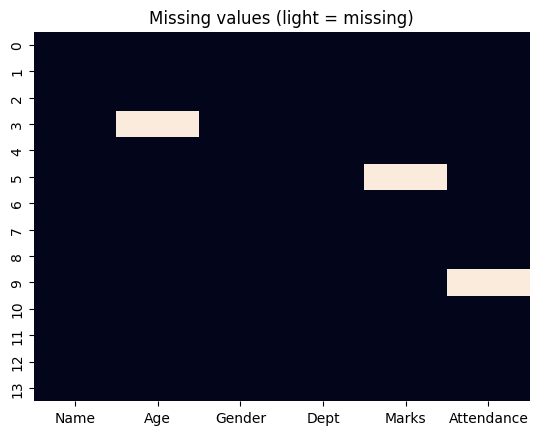

In [5]:
print(df.isnull().sum())
sns.heatmap(df.isnull(), cbar=False); plt.title('Missing values (light = missing)'); plt.show()

## 3. Handle missing values
Numeric → **mean** (or median if there are outliers). Categorical → **mode**.

In [6]:
clean = df.copy()
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].mean())          # change to .median() if you prefer
for c in cat_cols:
    clean[c] = clean[c].fillna(clean[c].mode()[0])
print(clean.isnull().sum().sum(), 'missing values left')
clean

0 missing values left


,Name,Age,Gender,Dept,Marks,Attendance
0,Asha,20.000000,F,CS,78.000000,85.000000
1,Ravi,21.000000,M,IT,65.000000,70.000000
2,Meena,22.000000,F,CS,88.000000,92.000000
3,Kiran,26.769231,M,ME,72.000000,80.000000
4,Sara,20.000000,F,IT,91.000000,95.000000
5,Tom,23.000000,M,CS,76.846154,60.000000
6,Neha,21.000000,F,ME,55.000000,58.000000
7,Arjun,22.000000,M,IT,82.000000,88.000000
8,Divya,20.000000,F,CS,95.000000,97.000000
9,Karan,24.000000,M,ME,45.000000,81.846154


## 4. Duplicates

In [7]:
print('Duplicate rows:', clean.duplicated().sum())
clean = clean.drop_duplicates().reset_index(drop=True)
print('Rows after removing duplicates:', len(clean))

Duplicate rows: 1
Rows after removing duplicates: 13


## 5. Outliers (IQR rule: outside Q1 − 1.5·IQR … Q3 + 1.5·IQR)

In [8]:
for c in num_cols:
    q1, q3 = clean[c].quantile(.25), clean[c].quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = clean[(clean[c] < lo) | (clean[c] > hi)]
    print(f'{c}: Q1={q1:.2f} Q3={q3:.2f} IQR={iqr:.2f} limits=({lo:.2f}, {hi:.2f}) outliers={out[c].tolist()}')

Age: Q1=21.00 Q3=23.00 IQR=2.00 limits=(18.00, 26.00) outliers=[26.76923076923077, 90.0]
Marks: Q1=65.00 Q3=88.00 IQR=23.00 limits=(30.50, 122.50) outliers=[]
Attendance: Q1=70.00 Q3=92.00 IQR=22.00 limits=(37.00, 125.00) outliers=[]


In [9]:
# Remove outliers from the columns listed here (edit the list; use [] to skip)
OUTLIER_COLS = ['Age']
nooutlier = clean.copy()
for c in OUTLIER_COLS:
    q1, q3 = nooutlier[c].quantile(.25), nooutlier[c].quantile(.75)
    iqr = q3 - q1
    nooutlier = nooutlier[(nooutlier[c] >= q1-1.5*iqr) & (nooutlier[c] <= q3+1.5*iqr)]
print(len(clean), '->', len(nooutlier), 'rows')

13 -> 11 rows


## 6. Scaling (Min-Max → 0..1, Z-score → mean 0, std 1)

In [10]:
scaled = nooutlier.copy()
for c in num_cols:
    scaled[c+'_minmax'] = (scaled[c] - scaled[c].min()) / (scaled[c].max() - scaled[c].min())
    scaled[c+'_zscore'] = (scaled[c] - scaled[c].mean()) / scaled[c].std()
scaled.round(3)

,Name,Age,Gender,Dept,Marks,Attendance,Age_minmax,Age_zscore,Marks_minmax,Marks_zscore,Attendance_minmax,Attendance_zscore
0,Asha,20.0,F,CS,78.000,85.000,0.00,-1.125,0.611,0.071,0.659,0.215
1,Ravi,21.0,M,IT,65.000,70.000,0.25,-0.351,0.370,-0.699,0.293,-0.825
2,Meena,22.0,F,CS,88.000,92.000,0.50,0.422,0.796,0.663,0.829,0.700
4,Sara,20.0,F,IT,91.000,95.000,0.00,-1.125,0.852,0.841,0.902,0.908
5,Tom,23.0,M,CS,76.846,60.000,0.75,1.195,0.590,0.002,0.049,-1.518
6,Neha,21.0,F,ME,55.000,58.000,0.25,-0.351,0.185,-1.291,0.000,-1.656
7,Arjun,22.0,M,IT,82.000,88.000,0.50,0.422,0.685,0.308,0.732,0.423
8,Divya,20.0,F,CS,95.000,97.000,0.00,-1.125,0.926,1.078,0.951,1.047
9,Karan,24.0,M,ME,45.000,81.846,1.00,1.968,0.000,-1.883,0.582,-0.003
10,Pooja,21.0,F,IT,70.000,75.000,0.25,-0.351,0.463,-0.403,0.415,-0.478


## 7. Encoding categorical columns (text → numbers)

In [11]:
encoded = pd.get_dummies(nooutlier, columns=cat_cols, dtype=int)   # one-hot
encoded.head()

,Name,Age,Marks,Attendance,Gender_F,Gender_M,Dept_CS,Dept_IT,Dept_ME
0,Asha,20.0,78.000000,85.0,1,0,1,0,0
1,Ravi,21.0,65.000000,70.0,0,1,0,1,0
2,Meena,22.0,88.000000,92.0,1,0,1,0,0
4,Sara,20.0,91.000000,95.0,1,0,0,1,0
5,Tom,23.0,76.846154,60.0,0,1,1,0,0


In [12]:
label = nooutlier.copy()                                           # label encoding
for c in cat_cols:
    label[c] = label[c].astype('category').cat.codes
label.head()

,Name,Age,Gender,Dept,Marks,Attendance
0,Asha,20.0,0,0,78.000000,85.0
1,Ravi,21.0,1,1,65.000000,70.0
2,Meena,22.0,0,0,88.000000,92.0
4,Sara,20.0,0,1,91.000000,95.0
5,Tom,23.0,1,0,76.846154,60.0


## 8. Visualisation

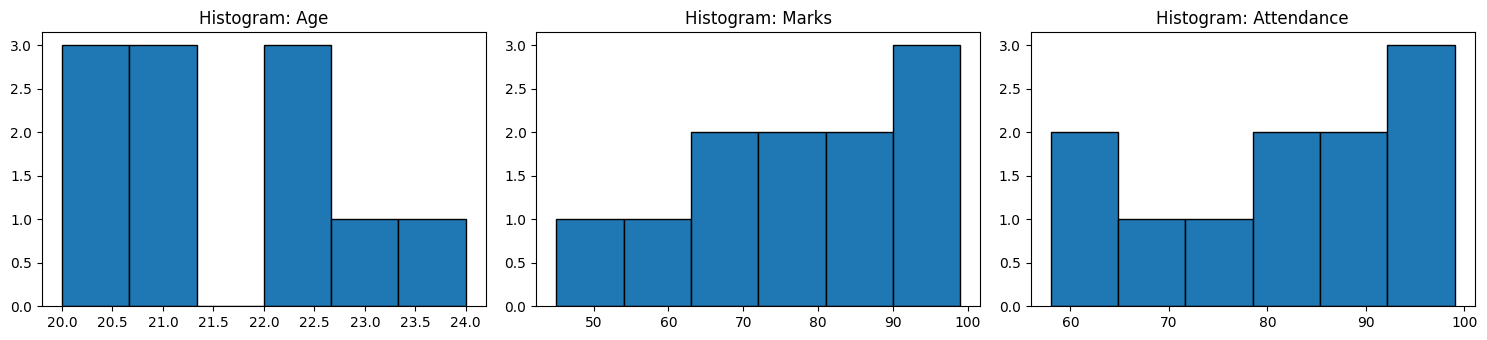

In [13]:
fig, ax = plt.subplots(1, len(num_cols), figsize=(5*len(num_cols), 3.5))
ax = np.atleast_1d(ax)
for a, c in zip(ax, num_cols):
    a.hist(nooutlier[c], bins=6, edgecolor='black'); a.set_title('Histogram: '+c)
plt.tight_layout(); plt.show()

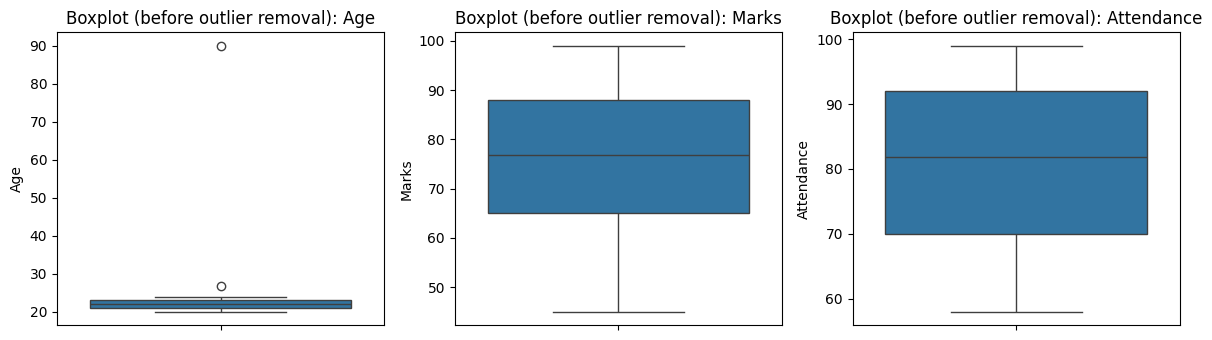

In [14]:
fig, ax = plt.subplots(1, len(num_cols), figsize=(4*len(num_cols), 3.5))
ax = np.atleast_1d(ax)
for a, c in zip(ax, num_cols):
    sns.boxplot(y=clean[c], ax=a); a.set_title('Boxplot (before outlier removal): '+c)
plt.tight_layout(); plt.show()

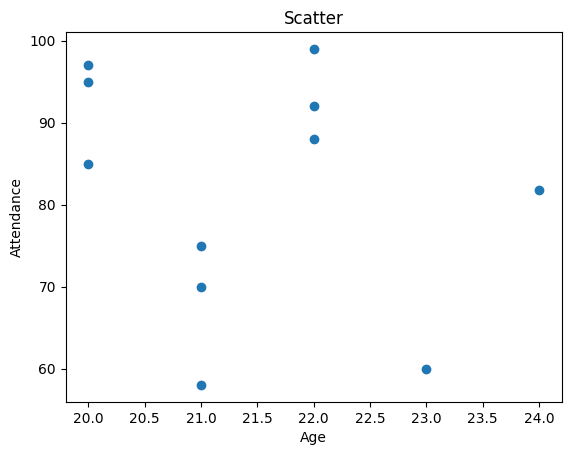

In [15]:
# Scatter plot of the first two numeric columns (edit X_COL / Y_COL)
X_COL, Y_COL = num_cols[0], num_cols[-1]
plt.scatter(nooutlier[X_COL], nooutlier[Y_COL]); plt.xlabel(X_COL); plt.ylabel(Y_COL); plt.title('Scatter'); plt.show()

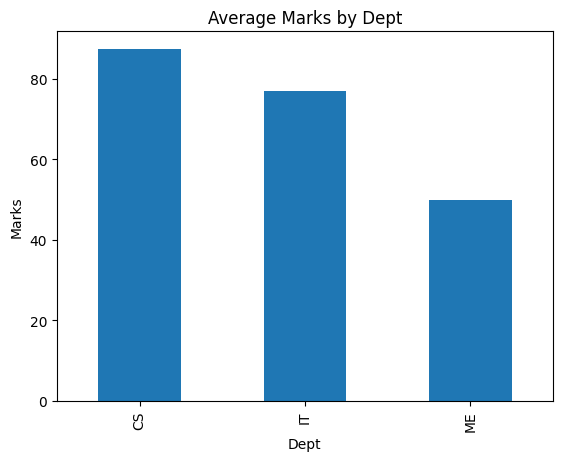

In [16]:
# Bar chart: average of a numeric column per category (edit CAT / NUM)
CAT, NUM = cat_cols[-1], num_cols[-2]
nooutlier.groupby(CAT)[NUM].mean().plot(kind='bar', title=f'Average {NUM} by {CAT}'); plt.ylabel(NUM); plt.show()

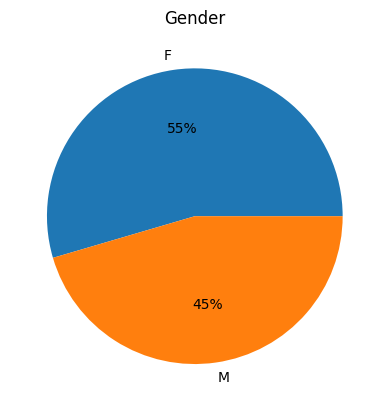

In [17]:
# Pie chart of a categorical column
nooutlier[cat_cols[0]].value_counts().plot(kind='pie', autopct='%1.0f%%', title=cat_cols[0]); plt.ylabel(''); plt.show()

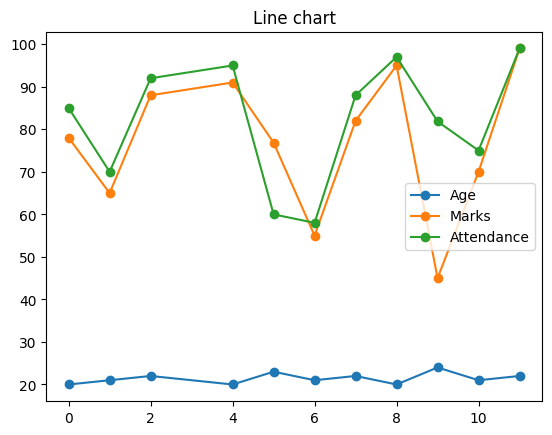

In [18]:
# Line chart (values in row order)
nooutlier[num_cols].plot(marker='o', title='Line chart'); plt.show()

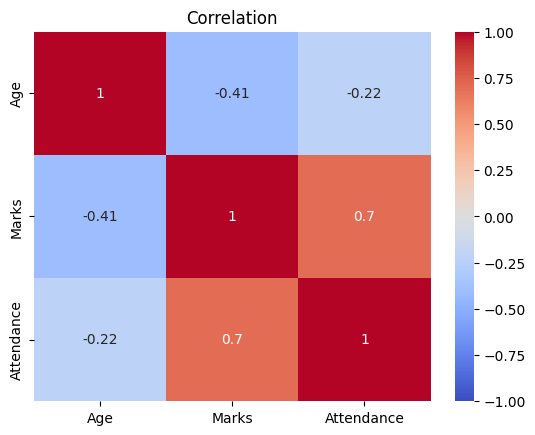

In [19]:
# Correlation heatmap (-1 .. +1)
sns.heatmap(nooutlier[num_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1); plt.title('Correlation'); plt.show()

## Viva one-liners
* **Missing values:** delete rows, mean/median/mode, forward-fill, or predict.
* **Outlier (IQR):** below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. **Boxplot dots = outliers.**
* **Min-Max** squeezes to 0–1; **Z-score** gives mean 0, std 1. Needed because distance-based methods (K-means, kNN) are dominated by big-range columns.
* **Encoding:** algorithms need numbers, so text categories become codes or one-hot columns.